# Customer Segmentation and Churn Modeling

This notebook combines **unsupervised learning** and **supervised learning** in one workflow:

1. K-Means discovers customer segments from Recency, Frequency, and Monetary (RFM) behavior.
2. A Random Forest classifier predicts whether a customer will make no purchase in the following 90 days. It uses RFM features and the K-Means segment.

The churn label is created from a later time window, while model features come only from earlier transactions. The notebook holds out customers for evaluation and fits the feature scaler and K-Means model only on the training split. This keeps the evaluation separate from model fitting.

## Data required

Keep `Online Retail.xlsx` in the same folder as this notebook. The notebook also supports `Online Retail.csv` as a fallback. It removes rows without a customer ID, cancellation invoices, and non-positive quantities or prices.

## Model interpretation

Cluster IDs are arbitrary categories, not a quality ranking. The classifier predicts churn risk, but its results depend on this dataset, the 90-day horizon, and the selected train/test split. Use the holdout metrics to judge performance before relying on predictions.

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

## 1. Load and clean transactions

Each row is a transaction line. Remove records without a customer ID, cancellation invoices, and non-positive quantity or price. Convert invoice dates to datetime and calculate line-item spend before aggregating customers.

In [49]:
try:
    df = pd.read_excel("Online Retail.xlsx")
except FileNotFoundError:
    df = pd.read_csv("Online Retail.csv", encoding="unicode_escape")

df = df.dropna(subset=["CustomerID"]).copy()
df["CustomerID"] = df["CustomerID"].astype(int).astype(str)
df = df.loc[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df.loc[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print(f"Cleaned transactions: {df.shape[0]:,}")
print(f"Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

Cleaned transactions: 397,884
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


## 2. Create the feature window and RFM table

Set the cutoff to 90 days before the dataset's last invoice. Transactions through the cutoff build the customer features; later transactions are held aside for churn labels. Recency is measured from one day after the final feature-window transaction. Frequency counts distinct invoices, and Monetary sums customer spend.

In [50]:
FEATURE_COLUMNS = ["Recency", "Frequency", "Monetary"]

cutoff_date = df["InvoiceDate"].max() - pd.Timedelta(days=90)
feature_df = df.loc[df["InvoiceDate"] <= cutoff_date]
target_df = df.loc[df["InvoiceDate"] > cutoff_date]
snapshot_date = feature_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = feature_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (snapshot_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum"),
)

print(f"Feature-window customers: {len(rfm):,}")
print(f"Target-window customers: {target_df['CustomerID'].nunique():,}")
print(f"Churn-label cutoff: {cutoff_date}")
rfm.describe().round(1)

Feature-window customers: 3,370
Target-window customers: 2,889
Churn-label cutoff: 2011-09-10 12:50:00


,Recency,Frequency,Monetary
count,3370.0,3370.0,3370.0
mean,94.9,3.5,1618.8
std,80.0,5.8,6151.4
min,1.0,1.0,2.9
25%,26.0,1.0,266.1
50%,74.0,2.0,566.0
75%,151.0,4.0,1388.9
max,283.0,132.0,178302.6


## 3. Create the churn target and holdout split

A customer is labeled `1` (churned) if they have no purchase in the target window and `0` otherwise. Split customers into stratified training and test sets before fitting either model. Stratification keeps the class proportions similar in both sets.

In [51]:
active_customers = target_df["CustomerID"].unique()
churn_labels = pd.Series(
    (~rfm.index.isin(active_customers)).astype("int8"),
    index=rfm.index,
    name="Churn",
)

print("Churn labels (0 = purchased again, 1 = no purchase):")
print(churn_labels.value_counts(normalize=True).sort_index().round(3))

X_train_rfm, X_test_rfm, y_train, y_test = train_test_split(
    rfm[FEATURE_COLUMNS],
    churn_labels,
    test_size=0.2,
    random_state=42,
    stratify=churn_labels,
)
print(f"Training customers: {len(X_train_rfm):,}")
print(f"Test customers: {len(X_test_rfm):,}")

Churn labels (0 = purchased again, 1 = no purchase):
Churn
0    0.57
1    0.43
Name: proportion, dtype: float64
Training customers: 2,696
Test customers: 674


## 4. Prepare the unsupervised model

Apply `log1p` to reduce the effect of highly skewed spending, then standardize RFM using only the training customers. The elbow curve is also computed on the training set. The existing workflow uses three clusters; keep `k=3` unless the elbow plot and validation justify changing it.

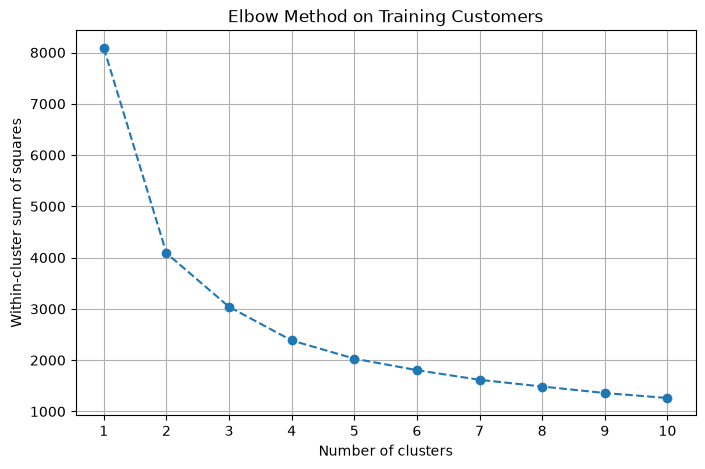

In [52]:
scaler = StandardScaler()
scaled_train_rfm = scaler.fit_transform(np.log1p(X_train_rfm[FEATURE_COLUMNS]))

cluster_range = range(1, 11)
wcss = []
for cluster_count in cluster_range:
    candidate = KMeans(
        n_clusters=cluster_count,
        init="k-means++",
        random_state=42,
        n_init=10,
    )
    candidate.fit(scaled_train_rfm)
    wcss.append(candidate.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(cluster_range, wcss, marker="o", linestyle="--")
plt.title("Elbow Method on Training Customers")
plt.xlabel("Number of clusters")
plt.ylabel("Within-cluster sum of squares")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.show()

## 5. Fit K-Means segments

Use the established `k=3` configuration and fit K-Means on scaled training RFM only. Assign each customer, including the held-out customers, to the nearest learned centroid. This lets the churn model use a segment without fitting the clusters on test data.

In [53]:
optimal_k = 3
kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=10,
)
kmeans.fit(scaled_train_rfm)

scaled_all_rfm = scaler.transform(np.log1p(rfm[FEATURE_COLUMNS]))
rfm["Cluster"] = kmeans.predict(scaled_all_rfm)

print(f"K-Means trained with k={optimal_k}")
print("Customer counts by segment:")
print(rfm["Cluster"].value_counts().sort_index())

K-Means trained with k=3
Customer counts by segment:
Cluster
0    1626
1     472
2    1272
Name: count, dtype: int64


## 6. Inspect segment profiles

Compare average Recency, Frequency, and Monetary values across the clusters. Cluster numbers are arbitrary IDs, so do not interpret a larger number as a better or more valuable segment.

In [54]:
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        Recency=("Recency", "mean"),
        Frequency=("Frequency", "mean"),
        Monetary=("Monetary", "mean"),
        CustomerCount=("Cluster", "size"),
    )
    .round(1)
)
print("Average RFM profile and customer count by segment:")
print(cluster_profile)

supervised_features = rfm[FEATURE_COLUMNS].copy()
supervised_features["Cluster"] = rfm["Cluster"].astype(str)
X_train_model = supervised_features.loc[X_train_rfm.index]
X_test_model = supervised_features.loc[X_test_rfm.index]

Average RFM profile and customer count by segment:
         Recency  Frequency  Monetary  CustomerCount
Cluster                                             
0          150.4        1.3     326.6           1626
1           18.2       12.2    7054.2            472
2           52.4        3.2    1253.7           1272


## 7. Train the supervised churn model

The classifier receives the three RFM values and the K-Means segment. The segment is one-hot encoded because its ID has no numeric order. A pipeline learns the log transform, scaling, and encoding from the training data. Class weighting helps account for the difference in churn and retained-customer counts.

In [55]:
numeric_preprocessor = Pipeline(
    steps=[
        ("log_transform", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("rfm", numeric_preprocessor, FEATURE_COLUMNS),
        ("segment", OneHotEncoder(handle_unknown="ignore"), ["Cluster"]),
    ]
)

churn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)
churn_model.fit(X_train_model, y_train)
print("Supervised churn classifier trained on the training customers.")

Supervised churn classifier trained on the training customers.


## 8. Evaluate on unseen customers

The report and confusion matrix summarize predictions for the held-out customers. ROC-AUC measures how well the model ranks churn risk across thresholds; compare it with the class balance and other metrics rather than using it alone. These results are a historical benchmark, not a guarantee of future performance.

In [56]:
churn_predictions = churn_model.predict(X_test_model)
churn_probabilities = churn_model.predict_proba(X_test_model)[:, 1]

print("Holdout classification report:")
print(
    classification_report(
        y_test,
        churn_predictions,
        labels=[0, 1],
        target_names=["Purchased again", "No purchase"],
        zero_division=0,
    )
)
print(f"Holdout ROC-AUC: {roc_auc_score(y_test, churn_probabilities):.3f}")

confusion_table = pd.DataFrame(
    confusion_matrix(y_test, churn_predictions, labels=[0, 1]),
    index=["Actual purchased again", "Actual no purchase"],
    columns=["Predicted purchased again", "Predicted no purchase"],
)
confusion_table

Holdout classification report:
                 precision    recall  f1-score   support

Purchased again       0.71      0.61      0.66       384
    No purchase       0.56      0.66      0.61       290

       accuracy                           0.63       674
      macro avg       0.63      0.64      0.63       674
   weighted avg       0.64      0.63      0.64       674

Holdout ROC-AUC: 0.682


,Predicted purchased again,Predicted no purchase
Actual purchased again,235,149
Actual no purchase,98,192
